In [1]:
from MultiAgent_DQ import *
import numpy as np
import pandas as pd  
import itertools
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
import sys
sys.path.append('../')
import tqdm
from utils import *


## reading results from simulations

In [2]:
df = pd.read_csv("../results/results_from_vectorized_script_raw.csv")
df_fixed = pd.read_csv("../results/results_vect_paramsfixed_time.csv")

In [3]:
#excluding lambda > 0.8
df_fixed = df_fixed[df_fixed['lambda']<=0.8]

In [4]:
def round_columns(df, columns, decimals):
    for column in columns:
        df[column] = df[column].round(decimals)
    return df

def round_to_quarters(df, columns, decimals):
    for column in columns:
        df[column] = (df[column]/ 0.25).round(decimals)* 0.25
    return df

# Columns to round
columns_to_round = ['delta', 'e', 'lambda', 'alpha']

# Apply the function to df
# Apply the function to df_fixed
df_fixed = round_columns(df_fixed, columns_to_round, 2)
df = round_columns(df, columns_to_round, 2)

df_fixed['M'] = df_fixed['M'].round(0)

In [5]:
columns = ['delta', 'e', 'lambda', 'alpha']

# Generate all pairwise combinations of the columns
pair_combinations = list(itertools.combinations(columns, 2))

# Display the pair combinations
print(pair_combinations)

[('delta', 'e'), ('delta', 'lambda'), ('delta', 'alpha'), ('e', 'lambda'), ('e', 'alpha'), ('lambda', 'alpha')]


/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/MultiAgent/../utils.py:634: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


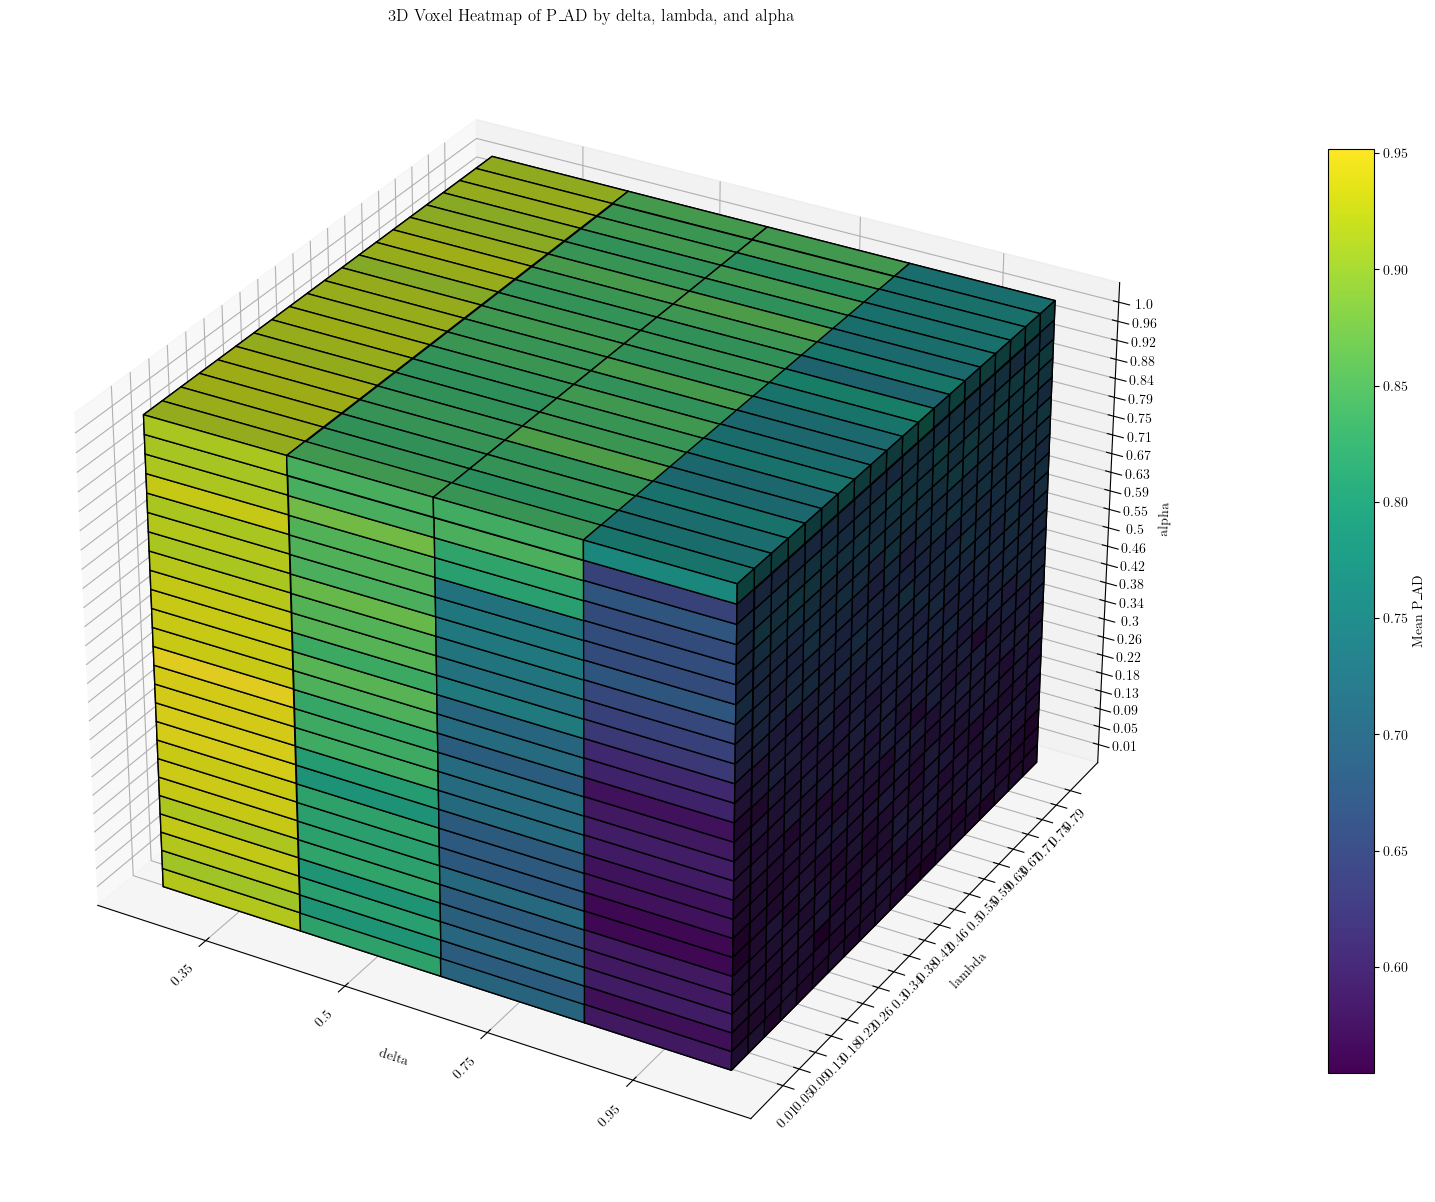

/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/MultiAgent/../utils.py:634: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


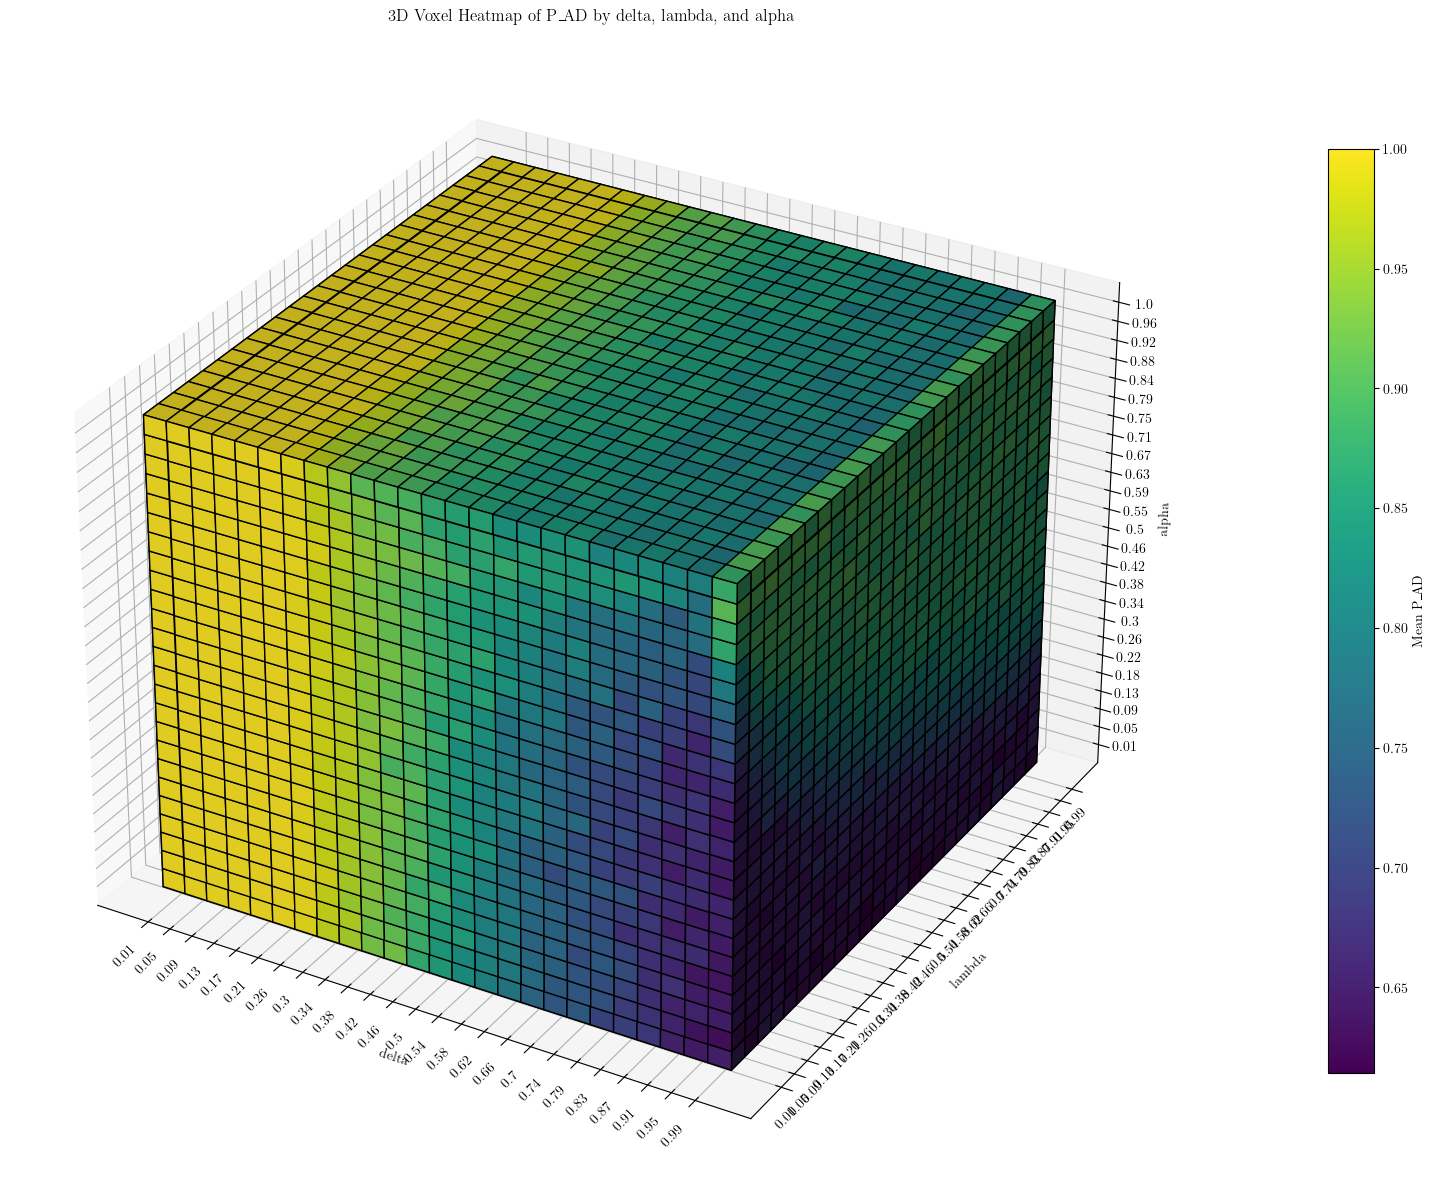

In [6]:
heatmap_3d_voxels(df_fixed, 'delta', 'lambda', 'alpha', value='P_AD')
heatmap_3d_voxels(df, 'delta', 'lambda', 'alpha', value='P_AD')


In [7]:
interactive_3d_voxel(df, 'delta', 'lambda', 'alpha', value='P_AD', html= False)

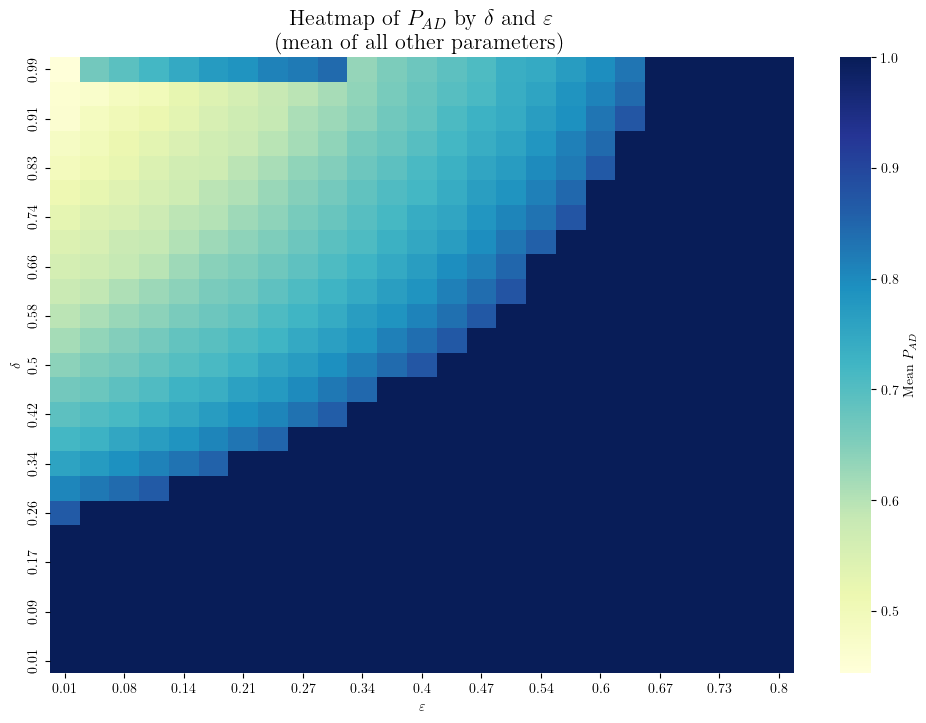

In [8]:
heatmap_mean(df, 'delta', 'e', 'P_AD')

In [9]:
#TODO: as alpha goes to 0, the effect of lambda in equilibrium decreases - flattening?
m = 5000

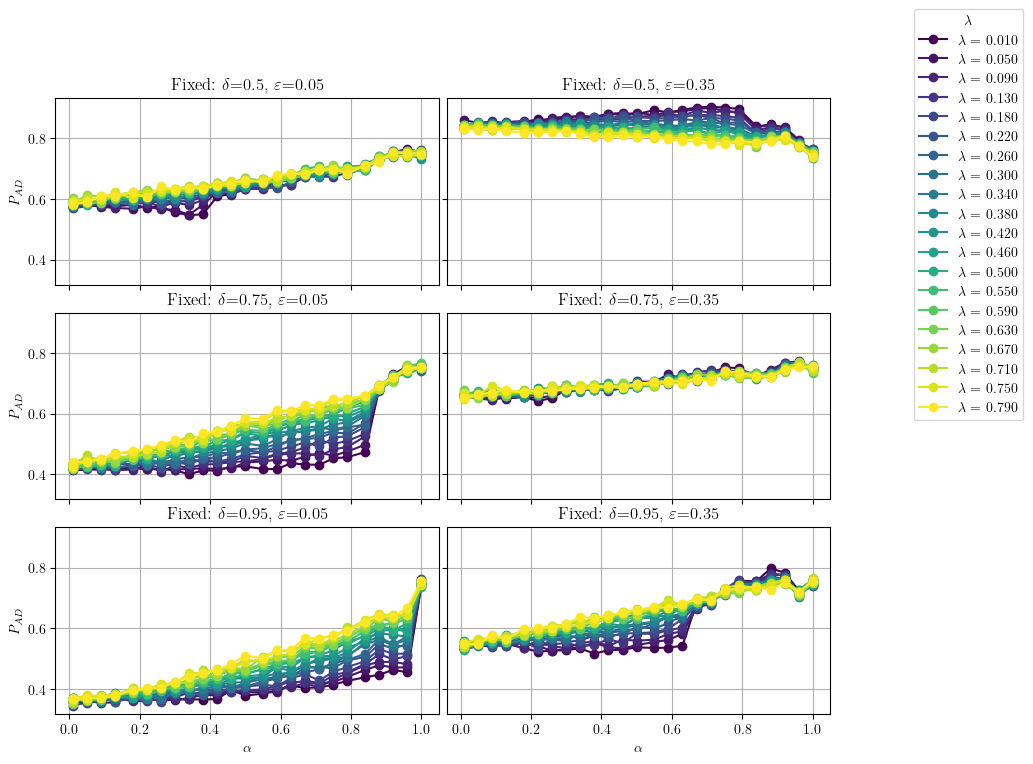

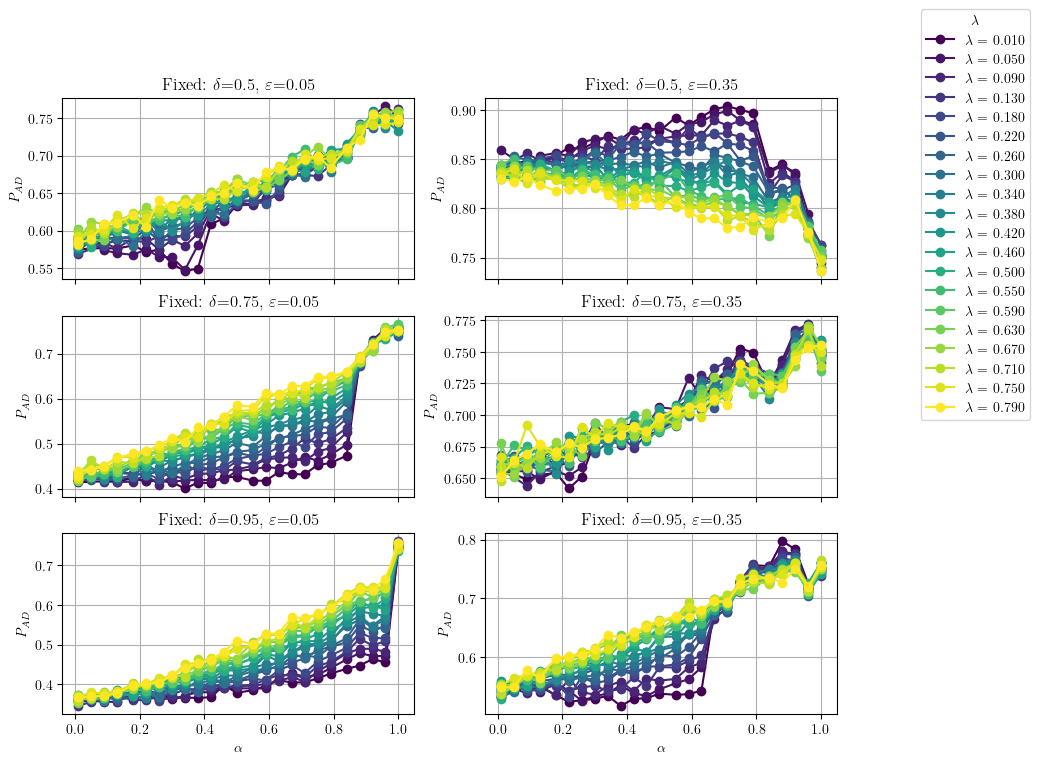

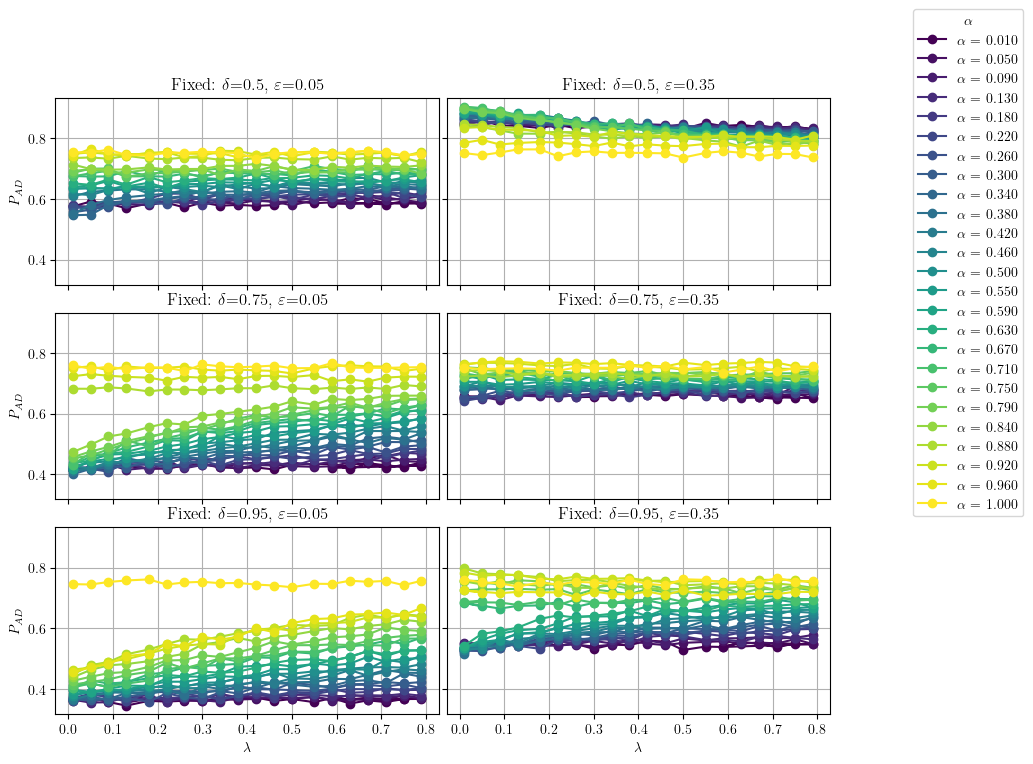

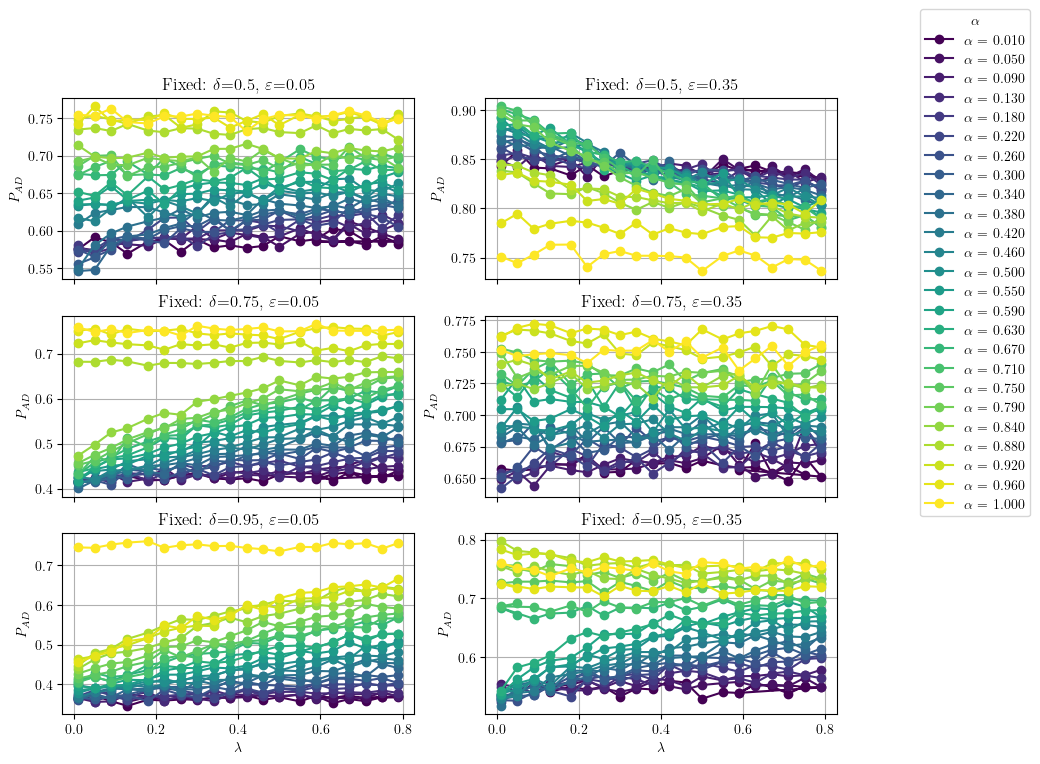

In [10]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.35},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.35},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.35},
]

m=5000
y = 'P_AD'
plot_multiple_panels(df_fixed, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=5000, use_same_scale=True)
plot_multiple_panels(df_fixed, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=5000, use_same_scale=False)
plot_multiple_panels(df_fixed, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=5000, use_same_scale=True)
plot_multiple_panels(df_fixed, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=5000, use_same_scale=False)